# 03. Analytical Visualizations
**COVID-19 Data Tracking System**

This notebook creates 15+ professional visualizations and a WordCloud to analyze infection trends, mortality patterns, country comparisons, and vaccination progress.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 12

PROJECT_ROOT = Path.cwd().parent
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "covid_cleaned.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED_PATH, parse_dates=['date'])
print(f"Cleaned data loaded: {df.shape}")

Cleaned data loaded: (572427, 66)


In [2]:
# Latest available data for each country
latest = df.sort_values('date').groupby('country').tail(1).copy()

# Global daily data
global_daily = df.groupby('date')[['new_cases', 'new_deaths', 'new_cases_7day_avg', 'new_deaths_7day_avg']].sum().reset_index()

print("Latest data shape:", latest.shape)
print("Global daily shape:", global_daily.shape)

Latest data shape: (239, 66)
Global daily shape: (2434, 5)


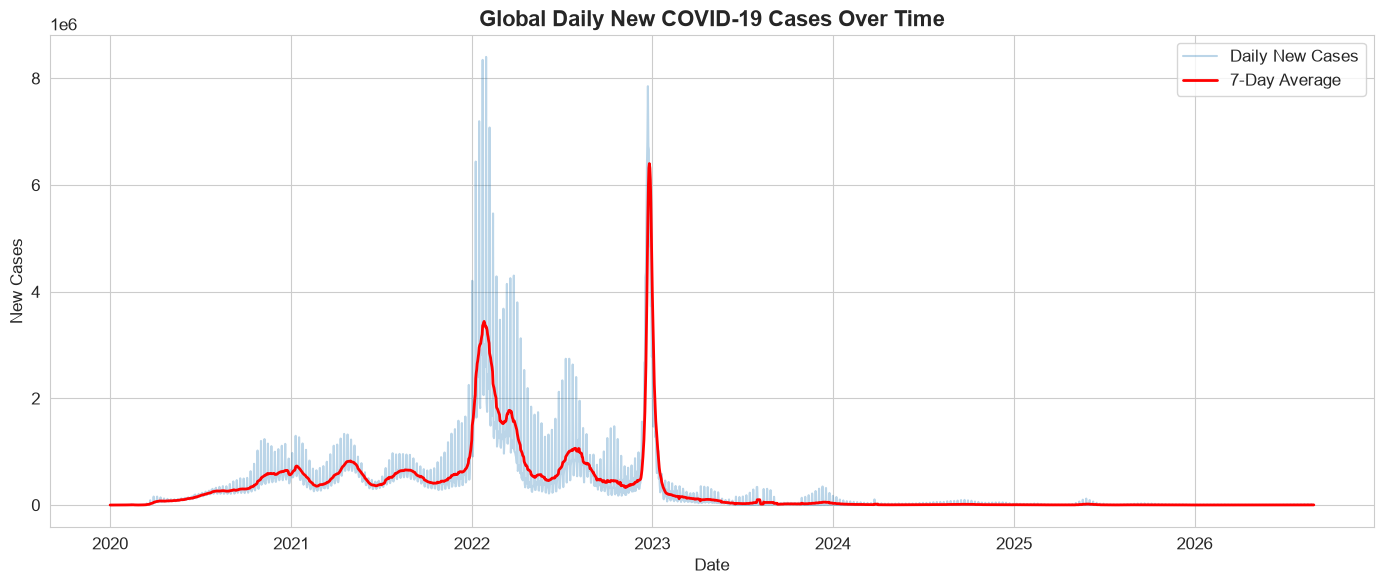

In [3]:
plt.figure(figsize=(14, 6))
plt.plot(global_daily['date'], global_daily['new_cases'], alpha=0.3, label='Daily New Cases')
plt.plot(global_daily['date'], global_daily['new_cases_7day_avg'], color='red', linewidth=2, label='7-Day Average')
plt.title('Global Daily New COVID-19 Cases Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('New Cases')
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / '01_global_new_cases.png', dpi=300, bbox_inches='tight')
plt.show()

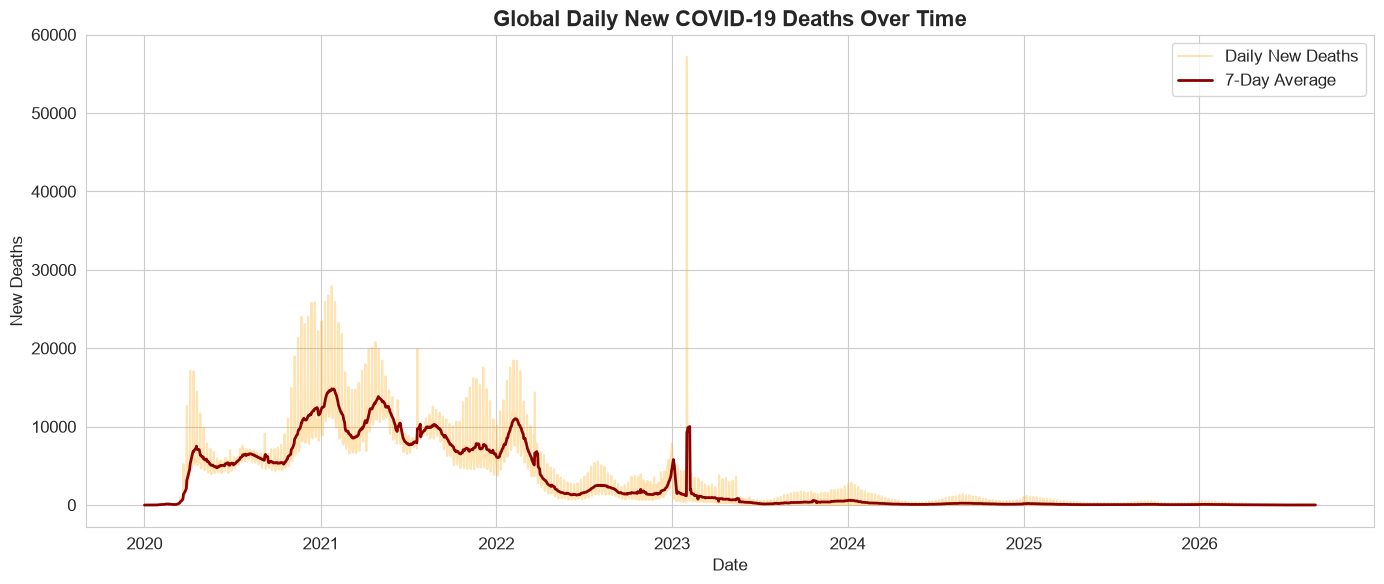

In [4]:
plt.figure(figsize=(14, 6))
plt.plot(global_daily['date'], global_daily['new_deaths'], alpha=0.3, color='orange', label='Daily New Deaths')
plt.plot(global_daily['date'], global_daily['new_deaths_7day_avg'], color='darkred', linewidth=2, label='7-Day Average')
plt.title('Global Daily New COVID-19 Deaths Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('New Deaths')
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / '02_global_new_deaths.png', dpi=300, bbox_inches='tight')
plt.show()

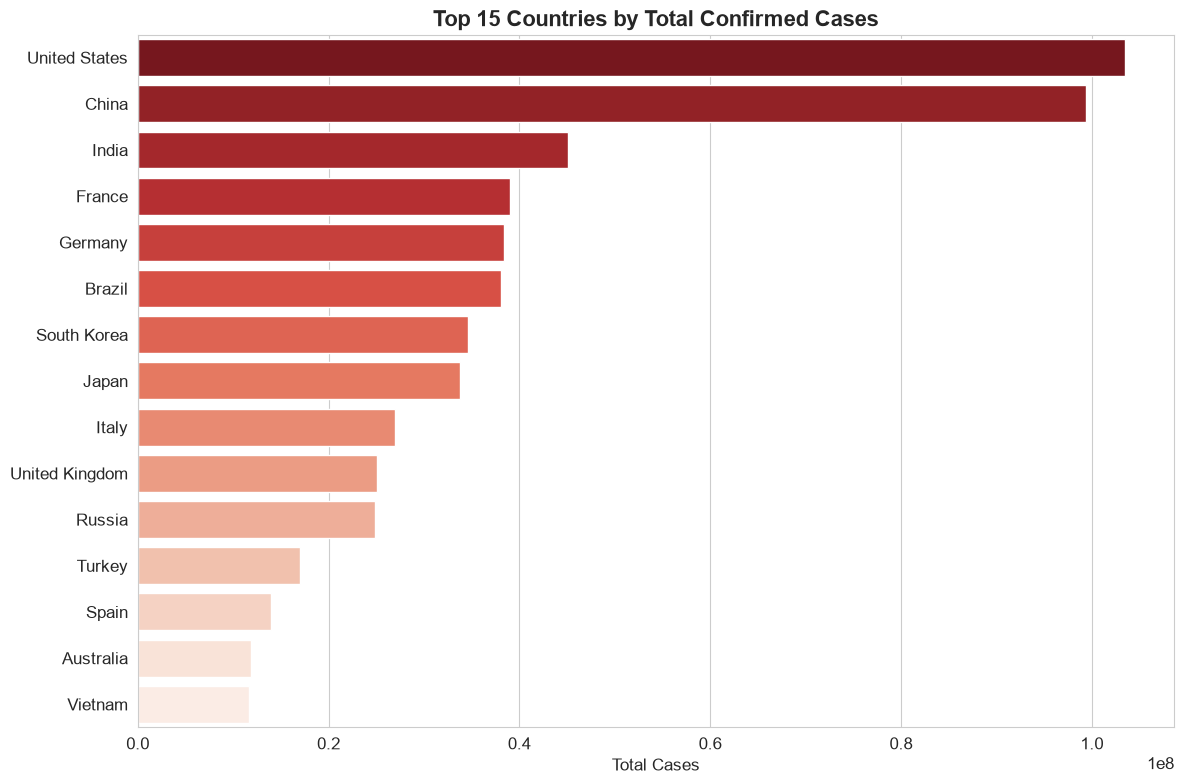

In [5]:
top_cases = latest.nlargest(15, 'total_cases')

plt.figure(figsize=(12, 8))
sns.barplot(data=top_cases, y='country', x='total_cases', palette='Reds_r')
plt.title('Top 15 Countries by Total Confirmed Cases', fontsize=16, fontweight='bold')
plt.xlabel('Total Cases')
plt.ylabel('')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '03_top15_total_cases.png', dpi=300, bbox_inches='tight')
plt.show()

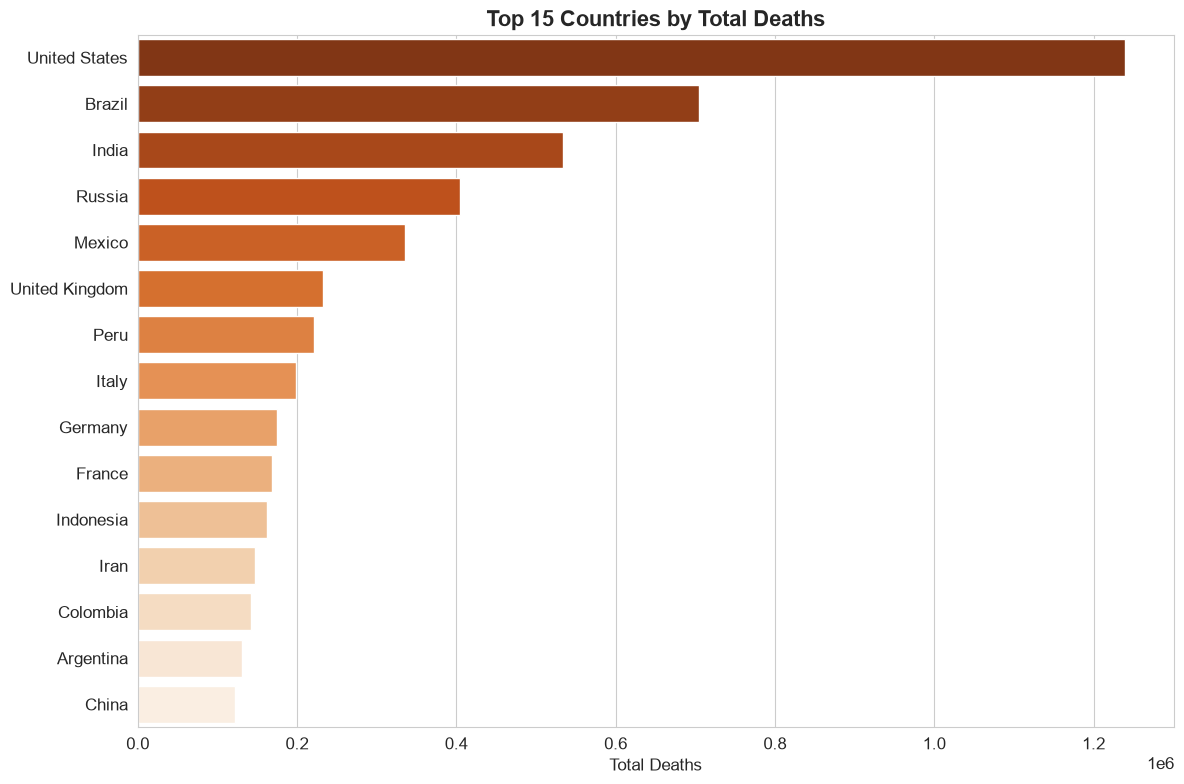

In [6]:
top_deaths = latest.nlargest(15, 'total_deaths')

plt.figure(figsize=(12, 8))
sns.barplot(data=top_deaths, y='country', x='total_deaths', palette='Oranges_r')
plt.title('Top 15 Countries by Total Deaths', fontsize=16, fontweight='bold')
plt.xlabel('Total Deaths')
plt.ylabel('')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '04_top15_total_deaths.png', dpi=300, bbox_inches='tight')
plt.show()

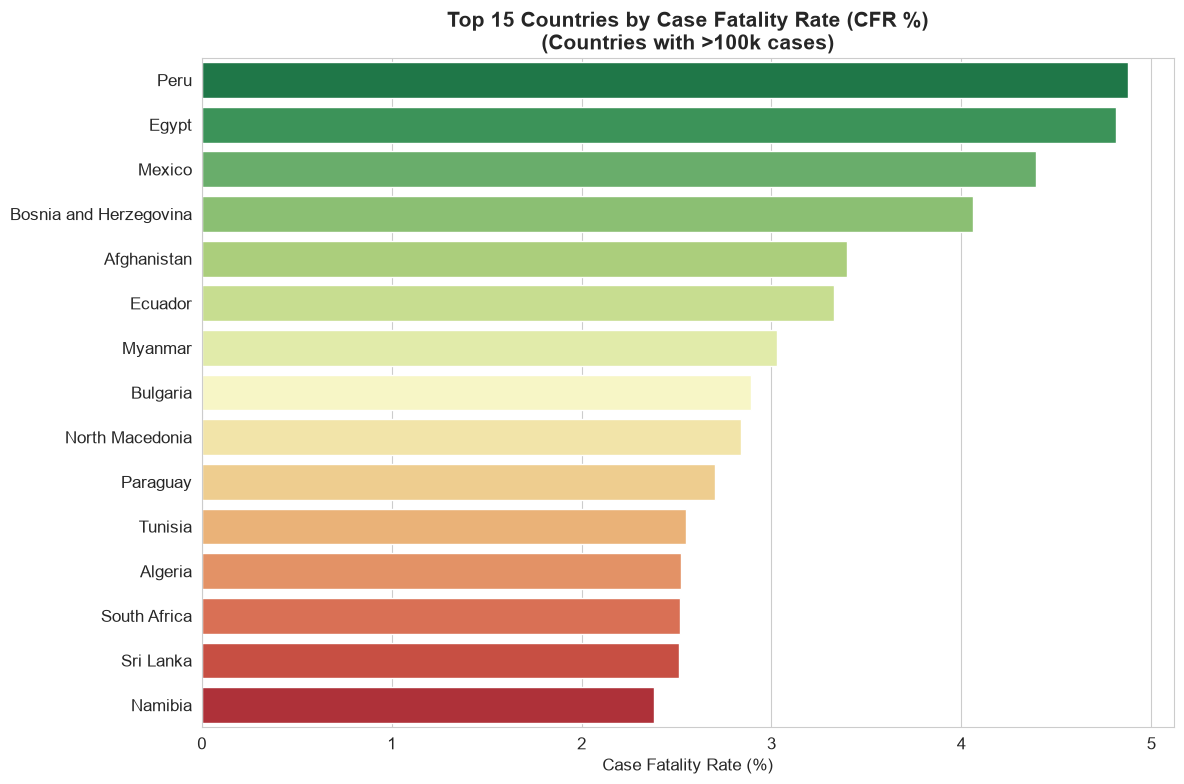

In [7]:
# Filter countries with significant cases
cfr_data = latest[latest['total_cases'] > 100000].nlargest(15, 'case_fatality_rate')

plt.figure(figsize=(12, 8))
sns.barplot(data=cfr_data, y='country', x='case_fatality_rate', palette='RdYlGn_r')
plt.title('Top 15 Countries by Case Fatality Rate (CFR %)\n(Countries with >100k cases)', fontsize=15, fontweight='bold')
plt.xlabel('Case Fatality Rate (%)')
plt.ylabel('')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '05_top15_cfr.png', dpi=300, bbox_inches='tight')
plt.show()

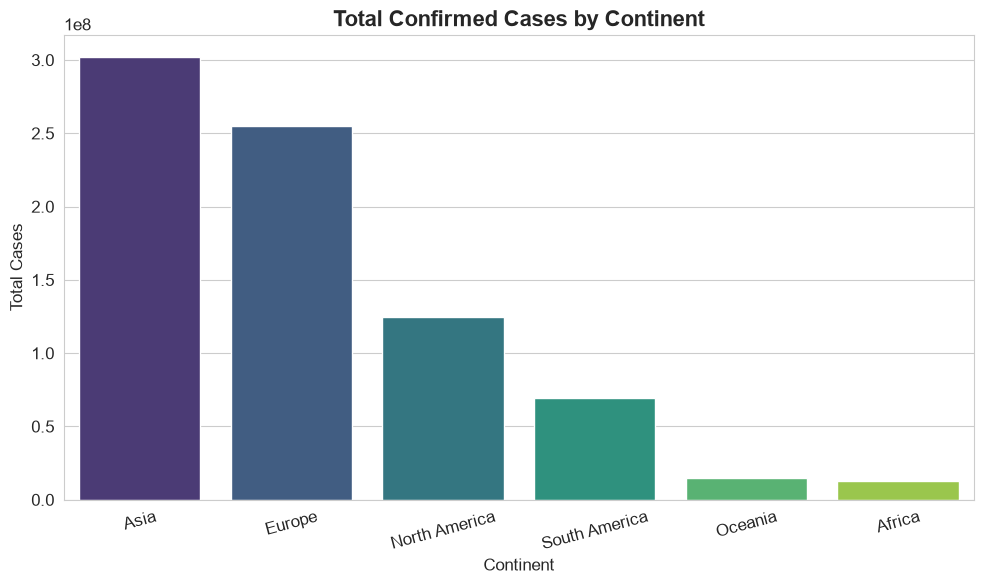

In [8]:
continent_cases = latest.groupby('continent')['total_cases'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=continent_cases.index, y=continent_cases.values, palette='viridis')
plt.title('Total Confirmed Cases by Continent', fontsize=16, fontweight='bold')
plt.xlabel('Continent')
plt.ylabel('Total Cases')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '06_continent_cases.png', dpi=300, bbox_inches='tight')
plt.show()

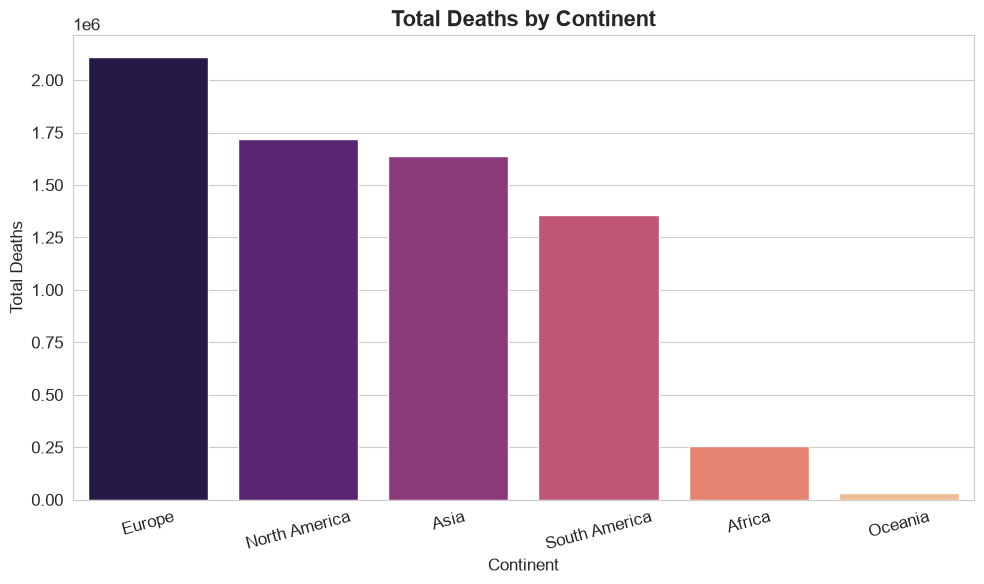

In [9]:
continent_deaths = latest.groupby('continent')['total_deaths'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=continent_deaths.index, y=continent_deaths.values, palette='magma')
plt.title('Total Deaths by Continent', fontsize=16, fontweight='bold')
plt.xlabel('Continent')
plt.ylabel('Total Deaths')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '07_continent_deaths.png', dpi=300, bbox_inches='tight')
plt.show()

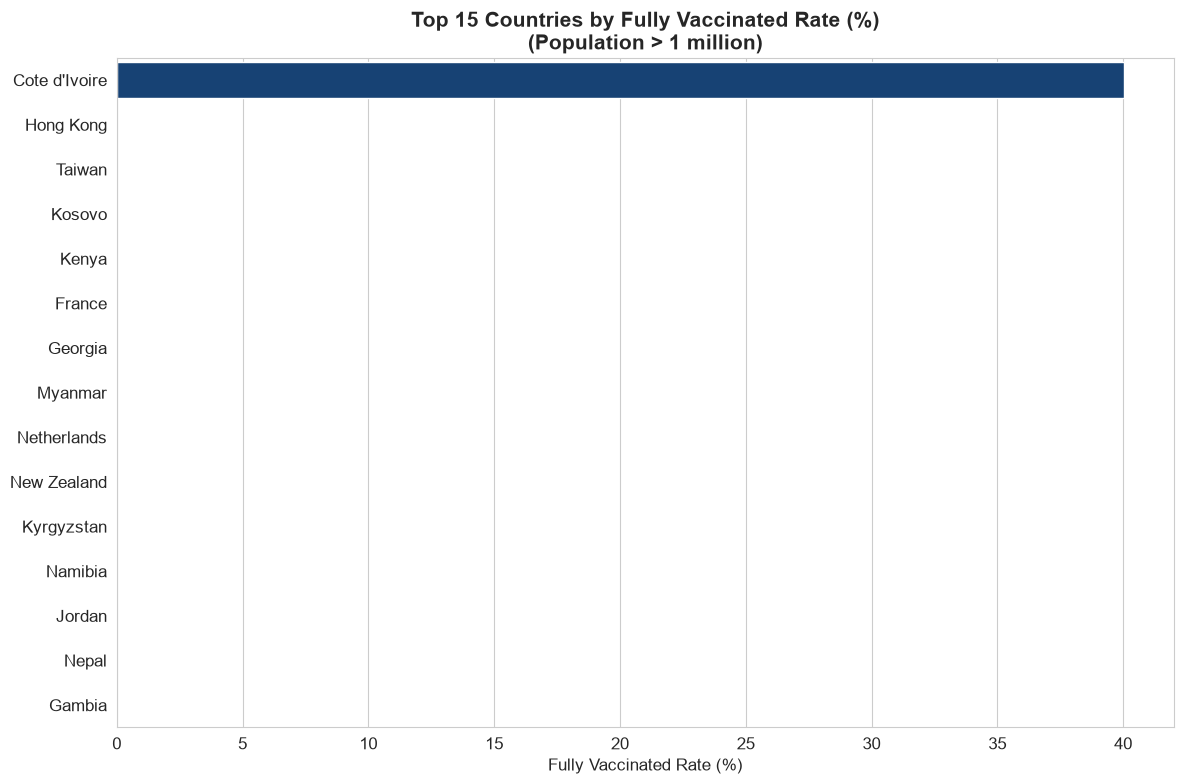

In [10]:
top_vax = latest[latest['population'] > 1000000].nlargest(15, 'fully_vaccinated_rate')

plt.figure(figsize=(12, 8))
sns.barplot(data=top_vax, y='country', x='fully_vaccinated_rate', palette='Blues_r')
plt.title('Top 15 Countries by Fully Vaccinated Rate (%)\n(Population > 1 million)', fontsize=15, fontweight='bold')
plt.xlabel('Fully Vaccinated Rate (%)')
plt.ylabel('')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '08_top15_vaccination.png', dpi=300, bbox_inches='tight')
plt.show()

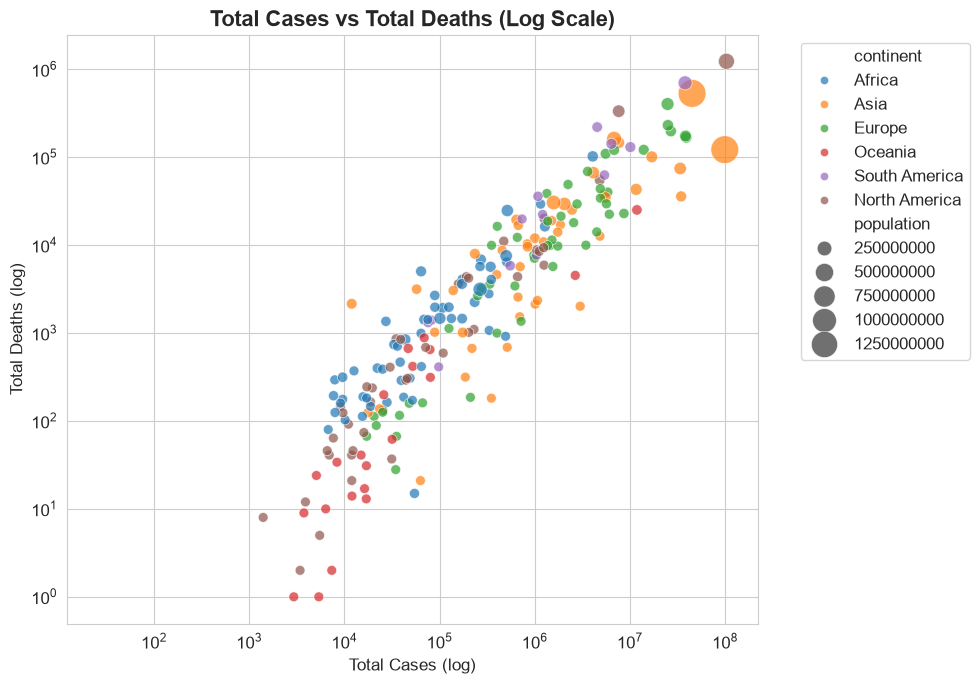

In [11]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=latest, x='total_cases', y='total_deaths', hue='continent', size='population',
                sizes=(50, 400), alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.title('Total Cases vs Total Deaths (Log Scale)', fontsize=16, fontweight='bold')
plt.xlabel('Total Cases (log)')
plt.ylabel('Total Deaths (log)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '09_cases_vs_deaths_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

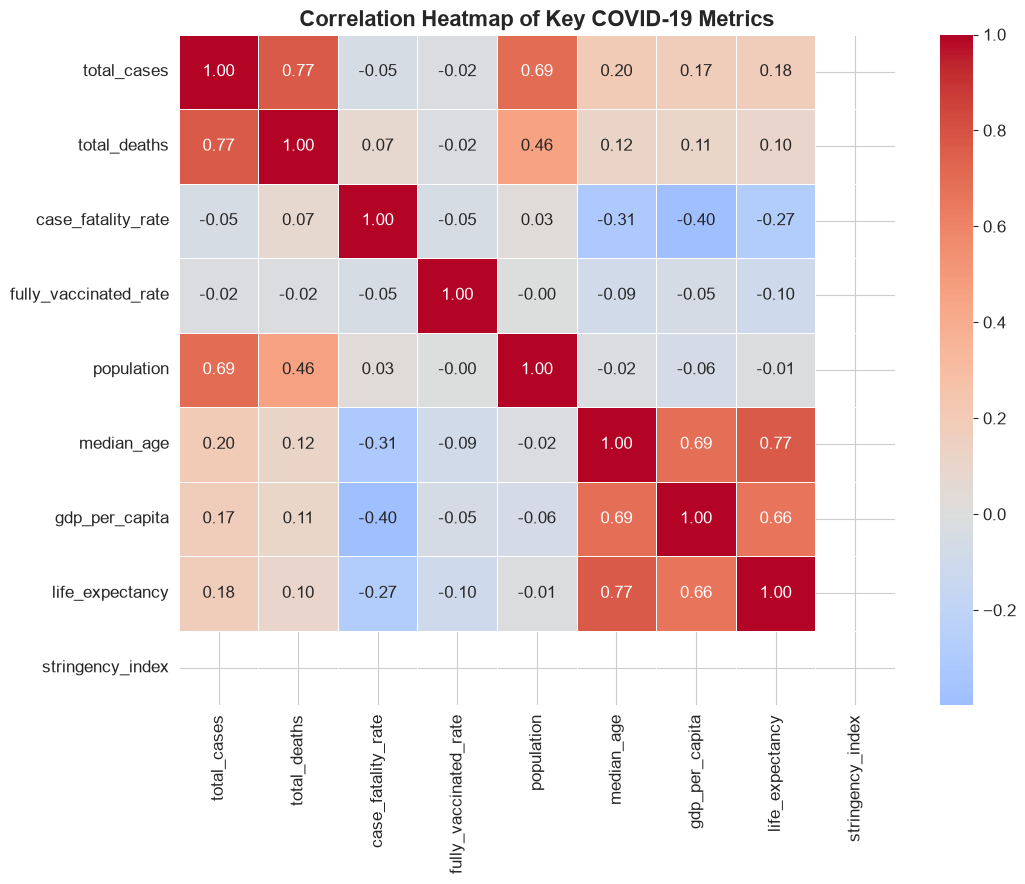

In [12]:
corr_cols = ['total_cases', 'total_deaths', 'case_fatality_rate', 
             'fully_vaccinated_rate', 'population', 'median_age', 
             'gdp_per_capita', 'life_expectancy', 'stringency_index']

corr_matrix = latest[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Key COVID-19 Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS_DIR / '10_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

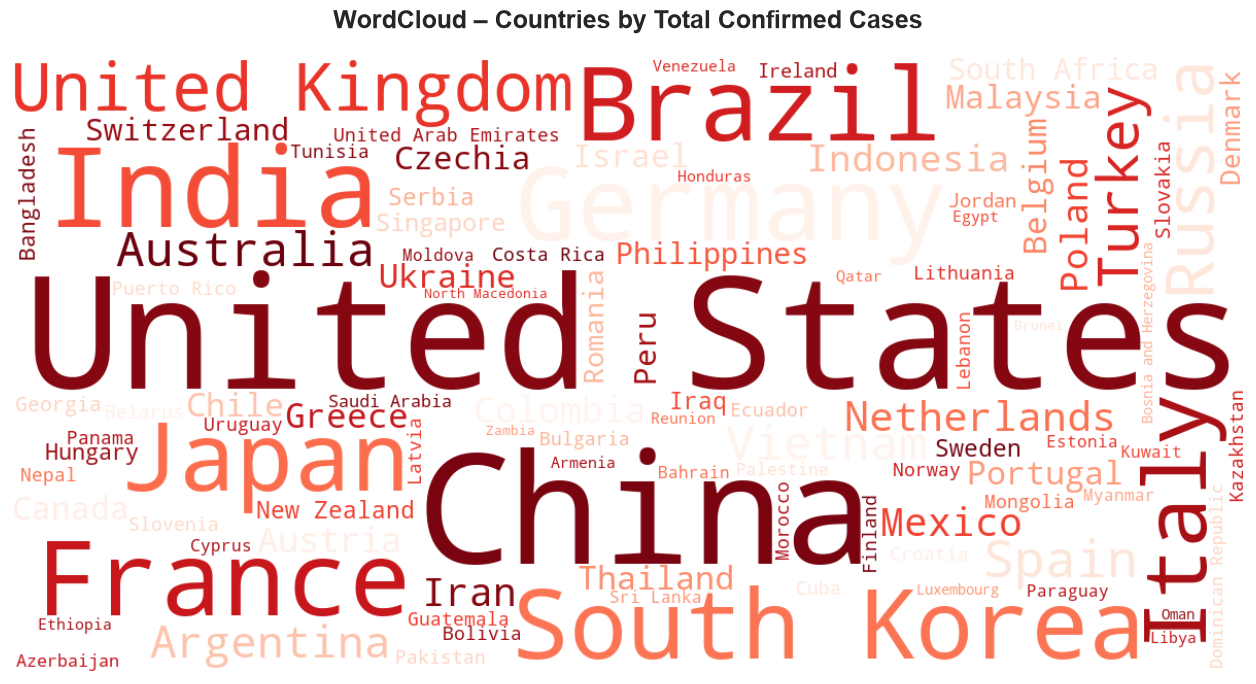

In [13]:
# Create frequency dictionary based on total cases
freq = dict(zip(latest['country'], latest['total_cases']))

wordcloud = WordCloud(
    width=1200, height=600,
    background_color='white',
    colormap='Reds',
    max_words=100
).generate_from_frequencies(freq)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud – Countries by Total Confirmed Cases', fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(REPORTS_DIR / '11_wordcloud_cases.png', dpi=300, bbox_inches='tight')
plt.show()

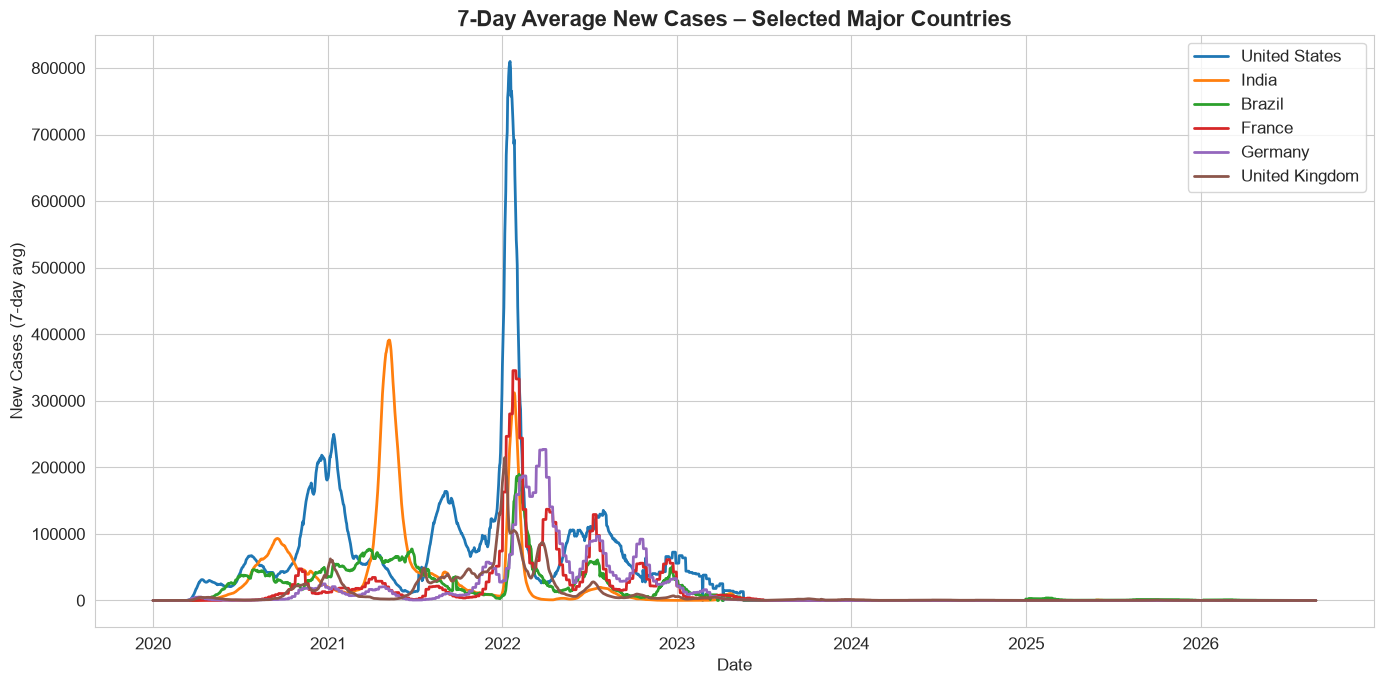

In [14]:
selected_countries = ['United States', 'India', 'Brazil', 'France', 'Germany', 'United Kingdom']
df_selected = df[df['country'].isin(selected_countries)]

plt.figure(figsize=(14, 7))
for country in selected_countries:
    country_data = df_selected[df_selected['country'] == country]
    plt.plot(country_data['date'], country_data['new_cases_7day_avg'], label=country, linewidth=2)

plt.title('7-Day Average New Cases – Selected Major Countries', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('New Cases (7-day avg)')
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / '12_selected_countries_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
print("="*60)
print("✅ All visualizations created successfully!")
print(f"Charts saved in: {REPORTS_DIR}")
print("="*60)
print("\nNext step → 04_insights_wordcloud.ipynb (or we can add more advanced analysis)")

✅ All visualizations created successfully!
Charts saved in: d:\OneDrive\Documents\Desktop\Resume Projects\covid19-data-tracking-system\reports

Next step → 04_insights_wordcloud.ipynb (or we can add more advanced analysis)
